In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data = pd.read_excel("data.xlsx", sheet_name = "Волгоградская")
data.head()

,Годы,Безработица,"Инвестиции на душу населения в фактических ценах, руб.",Уровень бедности,"Естественный прирост, промилле",Миграционный прирост на 10 тыс. чел. населения,"Индекс производительности труда, %","ВРП на душу населения, руб.","Уровень участия в рабочей силе, %"
0,2003,11.1,8256.20,21.40,-6.8,-13.43,99.7,47934.10,62.00
1,2004,9.3,11203.00,17.89,-5.8,-2.41,99.9,57928.00,65.30
2,2005,6.7,16136.99,17.20,-6.3,2.83,100.4,76740.60,63.70
3,2006,8.6,15032.40,11.90,-5.4,14.43,100.2,95683.40,65.59
4,2007,6.3,24729.70,13.00,-3.9,12.76,102.1,126313.09,66.09


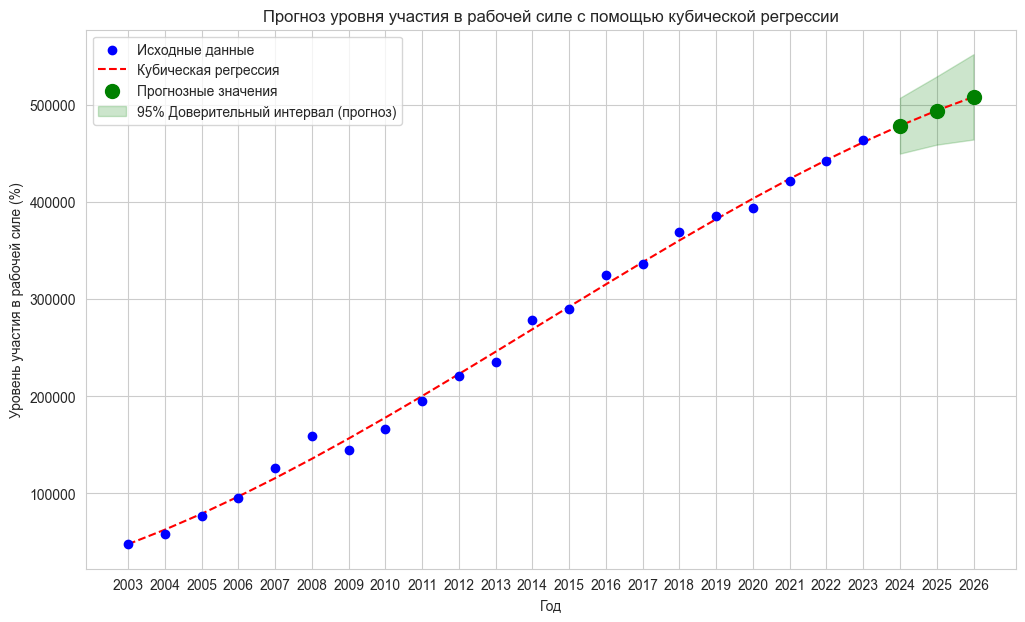

In [23]:
# Данные
years_original = np.array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
years_relative = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
labor_force_participation = np.array(data.iloc[:, 7])

# Создание полиномиальных признаков для statsmodels (включая константу)
X = pd.DataFrame({'X': years_relative})
X['X^2'] = X['X']**2
X['X^3'] = X['X']**3
X = sm.add_constant(X) # Добавляем константу для свободного члена

# Обучение модели OLS (Ordinary Least Squares)
model = OLS(labor_force_participation, X)
results = model.fit()

# Прогнозные годы (относительные)
forecast_years_relative = np.array([21, 22, 23]) # 2024, 2025, 2026

# Создание полиномиальных признаков для прогнозных годов
X_forecast = pd.DataFrame({'X': forecast_years_relative})
X_forecast['X^2'] = X_forecast['X']**2
X_forecast['X^3'] = X_forecast['X']**3
X_forecast = sm.add_constant(X_forecast) # Добавляем константу

# Получение прогнозов и доверительных интервалов
predictions = results.get_prediction(X_forecast)
summary_frame = predictions.summary_frame(alpha=0.05) # 95% доверительный интервал (alpha=0.05)

# Извлечение данных для графика
forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Годы для таблицы
forecast_actual_years = [2024, 2025, 2026]

# Вывод таблицы
forecast_table = pd.DataFrame({
    'Прогнозный год': forecast_actual_years,
    'Прогнозное значение (%)': forecast_values,
    'Нижняя граница 95% ДИ (%)': lower_bound_forecast,
    'Верхняя граница 95% ДИ (%)': upper_bound_forecast
})

# Объединяем исходные и прогнозные годы для оси X на графике
all_years = np.concatenate((years_original, np.array([2024, 2025, 2026])))
all_years_relative = np.concatenate((years_relative, forecast_years_relative))

# Получаем предсказанные значения для всего диапазона данных (для линии регрессии)
X_all = pd.DataFrame({'X': all_years_relative})
X_all['X^2'] = X_all['X']**2
X_all['X^3'] = X_all['X']**3
X_all = sm.add_constant(X_all)
predicted_labor_force_all = results.predict(X_all)

# Построение графика
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Исходные данные
plt.scatter(years_original, labor_force_participation, label='Исходные данные', color='blue', zorder=5)

# Линия кубической регрессии (проходящая через исходные и прогнозные точки)
plt.plot(all_years, predicted_labor_force_all, color='red', linestyle='--', label='Кубическая регрессия')

# Прогнозные точки
plt.scatter([2024, 2025, 2026], forecast_values, label='Прогнозные значения', color='green', marker='o', s=100, zorder=5)

# Доверительный интервал для прогноза
plt.fill_between([2024, 2025, 2026], lower_bound_forecast, upper_bound_forecast, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.title('Прогноз уровня участия в рабочей силе с помощью кубической регрессии')
plt.xlabel('Год')
plt.ylabel('Уровень участия в рабочей силе (%)')
plt.xticks(all_years) # Чтобы отображать все года на оси X
plt.legend()
plt.grid(True)
plt.show()

In [24]:
forecast_table.round(2).head()

,Прогнозный год,Прогнозное значение (%),Нижняя граница 95% ДИ (%),Верхняя граница 95% ДИ (%)
0,2024,478917.36,450163.22,507671.49
1,2025,494536.80,459368.86,529704.74
2,2026,508608.80,464663.39,552554.21
